<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Dataset:
   Haemoglobin       RBC     Glucose  Cholesterol        BMI
0    14.245071  5.014672   78.111447   212.709658  28.753135
1    13.292604  5.136471   98.012500   162.335040  22.935821
2    14.471533  5.449831  110.104874   216.088178  25.384483
3    15.784545  5.432281  110.939612   230.669136  23.150899
4    13.148770  3.973398  100.998691   202.403047  23.262015

Standardised Data:
   Haemoglobin       RBC   Glucose  Cholesterol       BMI
0     0.577318  0.275500 -1.517816     0.733661  0.847373
1    -0.104719  0.481170 -0.516799    -0.913256 -0.673997
2     0.739481  1.010313  0.091444     0.844116 -0.033612
3     1.679693  0.980679  0.133431     1.320817 -0.617749
4    -0.207714 -1.482808 -0.366595     0.396703 -0.588689

Covariance Matrix:
             Haemoglobin       RBC   Glucose  Cholesterol       BMI
Haemoglobin     1.000000  0.095147 -0.134197     0.065398 -0.031206
RBC             0.095147  1.000000 -0.032626    -0.101396 -0.142037
Glucose        -0.134197

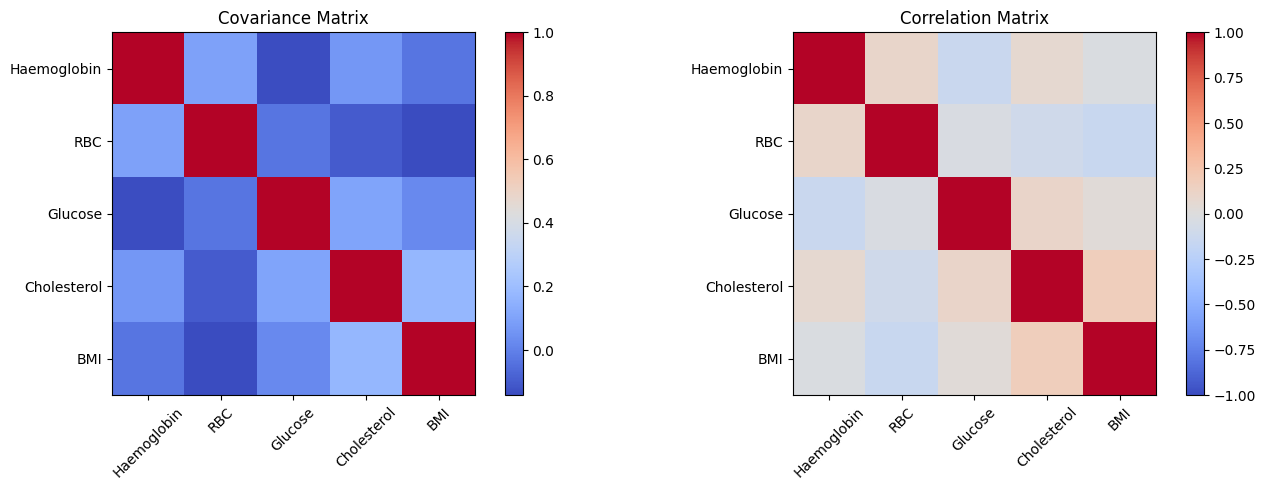


Sorted Eigenvalues:
[1.32511405 1.11031401 0.9828869  0.83771742 0.74396762]

Sorted Eigenvectors:
[[ 0.24613228 -0.74067287  0.23509617  0.26622328  0.51446823]
 [ 0.50426715 -0.0331167   0.53660467 -0.64546125 -0.20013277]
 [-0.36174773  0.45018115  0.66229107  0.10017661  0.46670193]
 [-0.51080366 -0.41117874  0.4104134   0.15383577 -0.61474145]
 [-0.54161955 -0.28031404 -0.2229722  -0.69195675  0.31551793]]

Percentage of Variance:
PC1: 26.50%
PC2: 22.21%
PC3: 19.66%
PC4: 16.75%
PC5: 14.88%


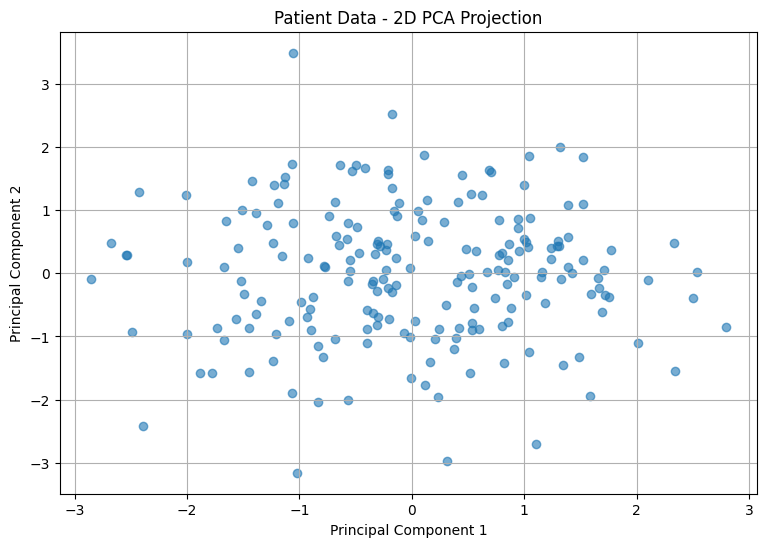

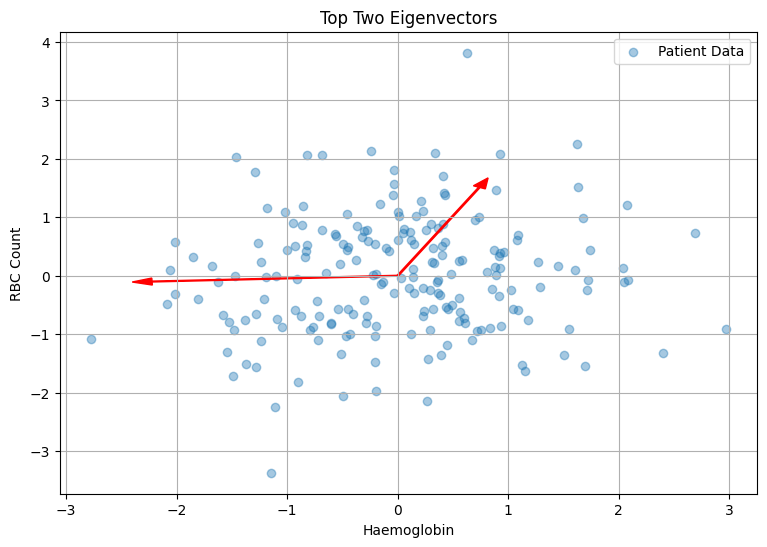

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Generate sample patient data
np.random.seed(42)

data = {
    'Haemoglobin': np.random.normal(13.5, 1.5, 200),
    'RBC': np.random.normal(4.8, 0.6, 200),
    'Glucose': np.random.normal(110, 20, 200),
    'Cholesterol': np.random.normal(190, 30, 200),
    'BMI': np.random.normal(25, 4, 200)
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df.head())

# Step 2: Standardise the features
mean = df.mean()
std = df.std()

standardized_data = (df - mean) / std

print("\nStandardised Data:")
print(standardized_data.head())

# Step 3: Calculate covariance and correlation
cov_matrix = standardized_data.cov()
corr_matrix = standardized_data.corr()

print("\nCovariance Matrix:")
print(cov_matrix)

print("\nCorrelation Matrix:")
print(corr_matrix)

# Plot covariance and correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(cov_matrix, cmap='coolwarm')
axes[0].set_title("Covariance Matrix")
axes[0].set_xticks(range(5))
axes[0].set_yticks(range(5))
axes[0].set_xticklabels(df.columns, rotation=45)
axes[0].set_yticklabels(df.columns)
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(corr_matrix, cmap='coolwarm',
                     vmin=-1, vmax=1)
axes[1].set_title("Correlation Matrix")
axes[1].set_xticks(range(5))
axes[1].set_yticks(range(5))
axes[1].set_xticklabels(df.columns, rotation=45)
axes[1].set_yticklabels(df.columns)
fig.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

# Step 4: Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort eigenvalues in descending order
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("\nSorted Eigenvalues:")
print(eigenvalues)

print("\nSorted Eigenvectors:")
print(eigenvectors)

# Step 5: Calculate explained variance percentage
explained_variance = (
    eigenvalues / np.sum(eigenvalues)
) * 100

print("\nPercentage of Variance:")
for i, value in enumerate(explained_variance):
    print(f"PC{i+1}: {value:.2f}%")

# Step 6: Project data onto first two principal components
projected_data = np.dot(
    standardized_data.values, eigenvectors[:, :2]
)

# Plot 2D PCA projection
plt.figure(figsize=(9, 6))

plt.scatter(
    projected_data[:, 0],
    projected_data[:, 1],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Patient Data - 2D PCA Projection")
plt.grid(True)

plt.show()

# Step 7: Plot eigenvectors as arrows
plt.figure(figsize=(9, 6))

plt.scatter(
    standardized_data.iloc[:, 0],
    standardized_data.iloc[:, 1],
    alpha=0.4,
    label="Patient Data"
)

for i in range(2):
    plt.arrow(
        0, 0,
        eigenvectors[0, i] * 3,
        eigenvectors[1, i] * 3,
        color='red',
        width=0.015,
        head_width=0.12
    )

plt.xlabel("Haemoglobin")
plt.ylabel("RBC Count")
plt.title("Top Two Eigenvectors")
plt.grid(True)
plt.legend()
plt.show()
